In [1]:

!pip install -q datasets pandas pillow


In [2]:

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [3]:

from pathlib import Path

project_dir = Path("/content/drive/MyDrive/IE7615_Project")
image_dir = project_dir / "images"

image_dir.mkdir(parents=True, exist_ok=True)

print("Project folder:", project_dir)


Project folder: /content/drive/MyDrive/IE7615_Project


In [4]:
from datasets import load_dataset

dataset = load_dataset(
    "AminDehnavi/flickr30k",
    split="train"
)

print(dataset)
print(dataset.column_names)
print(dataset[0])


README.md:   0%|          | 0.00/1.03k [00:00<?, ?B/s]

data/train-00000-of-00009.parquet: reconstructing file:   0%|          |  0.00B /  471MB            

data/train-00000-of-00009.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00009.parquet: reconstructing file:   0%|          |  0.00B /  475MB            

data/train-00001-of-00009.parquet: downloading bytes:           |  0.00B            

data/train-00002-of-00009.parquet: reconstructing file:   0%|          |  0.00B /  485MB            

... (11 outputs left out)

data/train-00008-of-00009.parquet: reconstructing file:   0%|          |  0.00B /  477MB            

data/train-00008-of-00009.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/31783 [00:00<?, ? examples/s]

Dataset({
    features: ['image', 'captions'],
    num_rows: 31783
})
['image', 'captions']
{'image': <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=333x500 at 0x7D627CB0AA50>, 'captions': ['Two young guys with shaggy hair look at their hands while hanging out in the yard .', 'Two young , White males are outside near many bushes .', 'Two men in green shirts are standing in a yard .', 'A man in a blue shirt standing in a garden .', 'Two friends enjoy time spent together .']}


In [5]:
import re

records = []
seen_captions = set()

for row in dataset:
    captions = row["captions"]

    if isinstance(captions, str):
        captions = [captions]

    for caption in captions:

        # lowercase
        cleaned = caption.lower().strip()

        # remove extra spaces
        cleaned = re.sub(r"\s+", " ", cleaned)

        # remove very short captions
        if len(cleaned.split()) < 4:
            continue

        # remove duplicate captions
        if cleaned in seen_captions:
            continue

        records.append({
            "image": row["image"],
            "caption": cleaned
        })

        seen_captions.add(cleaned)

        # use one valid caption per image
        break

    if len(records) >= 2000:
        break

print("Clean image-caption pairs:", len(records))
print("Example caption:", records[0]["caption"])

Clean image-caption pairs: 2000
Example caption: two young guys with shaggy hair look at their hands while hanging out in the yard .


In [6]:
from PIL import ImageOps
from pathlib import Path

# Folder where resized images will be saved
image_dir = Path("/content/drive/MyDrive/IE7615_Project/images")
image_dir.mkdir(parents=True, exist_ok=True)

cleaned_records = []

for i, record in enumerate(records):
    try:
        image = record["image"].convert("RGB")

        # Resize to 512x512 while preserving aspect ratio
        resized = ImageOps.pad(
            image,
            (512, 512),
            color=(255, 255, 255)
        )

        filename = f"image_{i:04d}.jpg"
        filepath = image_dir / filename

        resized.save(filepath, quality=90)

        cleaned_records.append({
            "image": f"images/{filename}",
            "caption": record["caption"]
        })

    except Exception as e:
        print(f"Skipped image {i}: {e}")

print("Images successfully saved:", len(cleaned_records))

Images successfully saved: 2000


In [7]:
import pandas as pd

df = pd.DataFrame(cleaned_records)

csv_path = "/content/drive/MyDrive/IE7615_Project/captions_clean.csv"

df.to_csv(csv_path, index=False)

print("CSV saved successfully!")
print("Total rows:", len(df))

display(df.head())

CSV saved successfully!
Total rows: 2000


,image,caption
0,images/image_0000.jpg,two young guys with shaggy hair look at their ...
1,images/image_0001.jpg,several men in hard hats are operating a giant...
2,images/image_0002.jpg,a child in a pink dress is climbing up a set o...
3,images/image_0003.jpg,someone in a blue shirt and hat is standing on...
4,images/image_0004.jpg,"two men , one in a gray shirt , one in a black..."


In [8]:
print("Total rows:", len(df))
print("Missing captions:", df["caption"].isna().sum())
print("Duplicate captions:", df["caption"].duplicated().sum())

assert len(df) == 2000
assert df["caption"].isna().sum() == 0
assert df["caption"].duplicated().sum() == 0

print("Validation passed!")

Total rows: 2000
Missing captions: 0
Duplicate captions: 0
Validation passed!


In [9]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu130
GPU available: True
GPU name: Tesla T4


In [10]:
!pip install -q diffusers transformers accelerate safetensors

In [11]:
import diffusers
import transformers
import accelerate

print("Diffusers:", diffusers.__version__)
print("Transformers:", transformers.__version__)
print("Accelerate:", accelerate.__version__)

Diffusers: 0.42.1
Transformers: 5.22.0
Accelerate: 1.15.0


In [12]:
import torch
from transformers import CLIPModel, CLIPTokenizer

model_name = "openai/clip-vit-base-patch32"

tokenizer = CLIPTokenizer.from_pretrained(model_name)
clip_model = CLIPModel.from_pretrained(model_name)

clip_model = clip_model.to("cuda")

print("CLIP model loaded successfully!")

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

... (2 outputs left out)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

CLIP model loaded successfully!


In [13]:
prompts = [
    "a dog running through a green field",
    "a red car parked beside a building",
    "a child playing with a colorful ball",
    "a cat sleeping on a sofa",
    "a beautiful sunset over the ocean"
]

inputs = tokenizer(
    prompts,
    padding=True,
    truncation=True,
    return_tensors="pt"
).to("cuda")

with torch.no_grad():
    outputs = clip_model.get_text_features(**inputs)

    if hasattr(outputs, "pooler_output"):
        text_embeddings = outputs.pooler_output
    else:
        text_embeddings = outputs

print("Number of prompts:", len(prompts))
print("Embedding shape:", text_embeddings.shape)

Number of prompts: 5
Embedding shape: torch.Size([5, 512])


In [17]:
import torch.nn.functional as F

all_embs = []
captions = df["caption"].tolist()
for i in range(0, len(captions), 64):
    batch = tokenizer(captions[i:i+64], padding=True, truncation=True, return_tensors="pt").to("cuda")
    with torch.no_grad():
        out = clip_model.get_text_features(**batch)
        out = out.pooler_output if hasattr(out, "pooler_output") else out
    all_embs.append(F.normalize(out, dim=-1).cpu())

caption_embeddings = torch.cat(all_embs)
torch.save(caption_embeddings, "/content/drive/MyDrive/IE7615_Project/text_embeddings.pt")
print("Caption embeddings shape:", caption_embeddings.shape)

q = tokenizer(["a dog playing outside"], return_tensors="pt").to("cuda")
with torch.no_grad():
    qe = clip_model.get_text_features(**q)
    qe = qe.pooler_output if hasattr(qe, "pooler_output") else qe
qe = F.normalize(qe, dim=-1).cpu()
top = (caption_embeddings @ qe.T).squeeze().topk(3).indices
for idx in top:
    print("-", captions[idx])

Caption embeddings shape: torch.Size([2000, 512])
- a dog prepares to catch a thrown object in a field with nearby cars .
- the dog is wading through shallow water while holding something in its mouth .
- two dogs are playing in a grassy field ; one dog is biting the ear of the other dog .


In [14]:
from diffusers import StableDiffusionPipeline
import torch

model_id = "runwayml/stable-diffusion-v1-5"

pipe = StableDiffusionPipeline.from_pretrained(
    model_id,
    torch_dtype=torch.float16
)

pipe = pipe.to("cuda")

print("Stable Diffusion loaded successfully!")

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Stable Diffusion loaded successfully!


In [15]:
from pathlib import Path
import pandas as pd

# Folder to save generated sample images
sample_dir = Path("/content/drive/MyDrive/IE7615_Project/sample_outputs")
sample_dir.mkdir(parents=True, exist_ok=True)

prompts = [
    "a dog running through a green field",
    "a red car parked beside a building",
    "a child playing with a colorful ball",
    "a cat sleeping on a sofa",
    "a beautiful sunset over the ocean"
]

results = []

for i, prompt in enumerate(prompts, start=1):
    image = pipe(
        prompt,
        num_inference_steps=30,
        guidance_scale=7.5
    ).images[0]

    filename = f"sample_{i}.png"
    filepath = sample_dir / filename
    image.save(filepath)

    results.append({
        "prompt_no": i,
        "prompt": prompt,
        "image_file": filename
    })

    print(f"Saved: {filepath}")

print("All 5 images generated successfully!")

  0%|          | 0/30 [00:00<?, ?it/s]

Saved: /content/drive/MyDrive/IE7615_Project/sample_outputs/sample_1.png


  0%|          | 0/30 [00:00<?, ?it/s]

Saved: /content/drive/MyDrive/IE7615_Project/sample_outputs/sample_2.png


  0%|          | 0/30 [00:00<?, ?it/s]

Saved: /content/drive/MyDrive/IE7615_Project/sample_outputs/sample_3.png


  0%|          | 0/30 [00:00<?, ?it/s]

Saved: /content/drive/MyDrive/IE7615_Project/sample_outputs/sample_4.png


  0%|          | 0/30 [00:00<?, ?it/s]

Saved: /content/drive/MyDrive/IE7615_Project/sample_outputs/sample_5.png
All 5 images generated successfully!


In [16]:
results_df = pd.DataFrame(results)

prompts_csv_path = "/content/drive/MyDrive/IE7615_Project/sample_prompts.csv"
results_df.to_csv(prompts_csv_path, index=False)

print("Prompt file saved:", prompts_csv_path)
display(results_df)

Prompt file saved: /content/drive/MyDrive/IE7615_Project/sample_prompts.csv


,prompt_no,prompt,image_file
0,1,a dog running through a green field,sample_1.png
1,2,a red car parked beside a building,sample_2.png
2,3,a child playing with a colorful ball,sample_3.png
3,4,a cat sleeping on a sofa,sample_4.png
4,5,a beautiful sunset over the ocean,sample_5.png


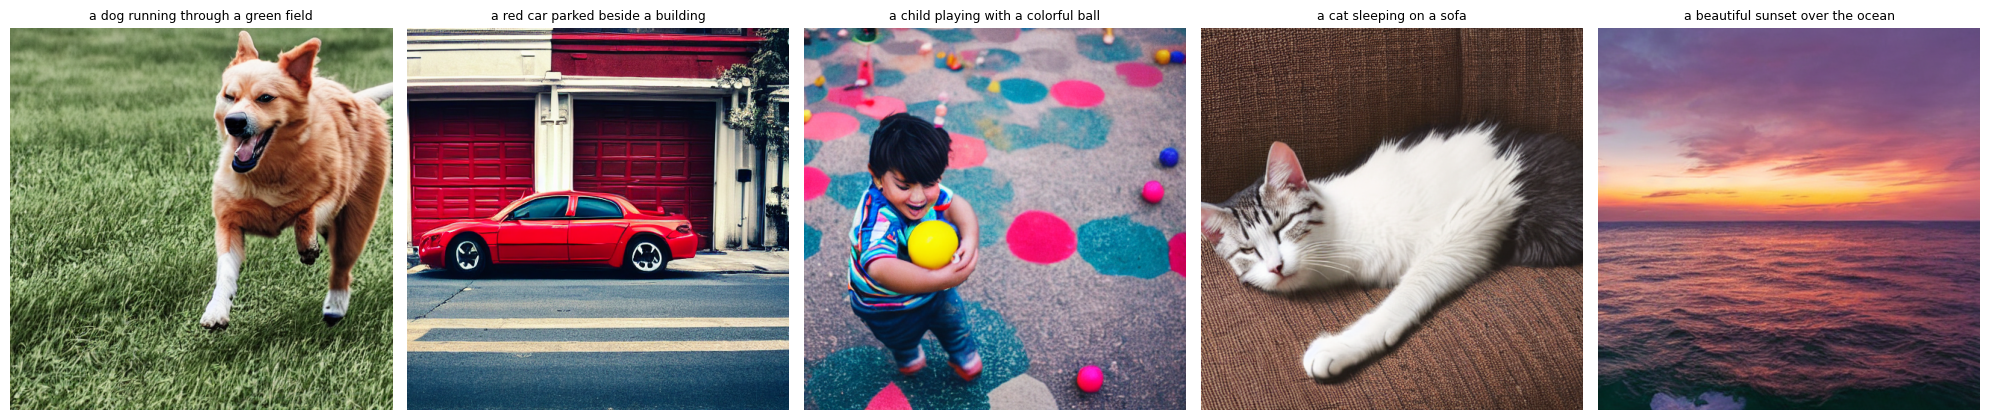

In [18]:
from PIL import Image
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 5, figsize=(20, 5))
for ax, row in zip(axes, results):
    ax.imshow(Image.open(sample_dir / row["image_file"]))
    ax.set_title(row["prompt"], fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()